# E-Commerce Retention Analytics: RFM Segmentation & Churn Prediction

**Business domain:** E-commerce / Retail Analytics / Marketing  
**Dataset:** Brazilian E-Commerce Public Dataset by Olist  
**Project type:** End-to-end analytics, machine learning and BI dashboard  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, SQL (SQLite), Power BI/Tableau, GitHub

## Notebook Guide

This notebook follows an end-to-end analytics workflow:

1. **Data preparation:** environment setup, dataset loading, quality checks and preprocessing.
2. **Customer analytics:** exploratory analysis, RFM metrics, RFM scoring, customer segmentation and cohort retention.
3. **Churn prediction:** churn definition, feature engineering, model training, evaluation and customer risk scoring.
4. **Business delivery:** SQL aggregation, retention KPIs, business insights and Power BI-ready exports.

## Project problem
E-commerce businesses need to understand customer value and identify customers who may stop purchasing. This project creates customer-level RFM measures, segments customers with K-Means, evaluates churn-classification models, and exports results for a marketing dashboard.

## Objectives
1. Clean order data and aggregate transaction/payment records to customer level.
2. Perform EDA, purchasing-trend analysis and cohort-retention analysis.
3. Calculate Recency, Frequency and Monetary values, RFM scores and a CLV proxy.
4. Create customer segments using K-Means and describe their business profiles.
5. Define 90-day inactivity as the project churn label and compare at least three classifiers.
6. Evaluate Accuracy, Precision, Recall, F1-score and ROC-AUC, emphasizing churn recall.
7. Produce 5–8 data-based business insights and export Power BI-ready datasets.


## Environment Setup and Library Imports

In [1]:
from pathlib import Path
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    RocCurveDisplay
)
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Change this path to the folder containing the extracted Olist CSV files.
DATA_DIR = Path(r"C:\Users\nihal\Downloads\archive (2)")
print("Libraries loaded.")
print("Dataset folder:", DATA_DIR.resolve())

Libraries loaded.
Dataset folder: C:\Users\nihal\Downloads\archive (2)


## Dataset Loading and Initial Inspection

In [2]:
required_files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "payments": "olist_order_payments_dataset.csv"
}

missing_files = [
    filename for filename in required_files.values()
    if not (DATA_DIR / filename).is_file()
]
if missing_files:
    raise FileNotFoundError(
        "CSV file(s) not found: " + ", ".join(missing_files) +
        "\nUpdate DATA_DIR to the folder containing these files."
    )

customers = pd.read_csv(DATA_DIR / required_files["customers"])
orders = pd.read_csv(DATA_DIR / required_files["orders"])
payments = pd.read_csv(DATA_DIR / required_files["payments"])
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Payments:", payments.shape)
display(customers.head())
display(orders.head())
display(payments.head())

Customers: (99441, 5)
Orders: (99441, 8)
Payments: (103886, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


## Data Quality Assessment and Preprocessing

In [3]:
print("Missing values in orders:")
display(orders.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)

# Use delivered orders with valid customer IDs and purchase dates.
orders_clean = orders.loc[
    orders["order_status"].eq("delivered")
    & orders["customer_id"].notna()
    & orders["order_purchase_timestamp"].notna()
].copy()

# Aggregate payment instalments by order before joining.
payments_by_order = payments.groupby("order_id", as_index=False).agg(
    order_payment_value=("payment_value", "sum")
)

orders_clean = orders_clean.merge(
    payments_by_order, on="order_id", how="left"
)
orders_clean["order_payment_value"] = orders_clean["order_payment_value"].fillna(0)

# Exclude negative payment totals for this analysis; refunds are not modelled separately.
orders_clean = orders_clean.loc[
    orders_clean["order_payment_value"] >= 0
].copy()
order_data = orders_clean.merge(
    customers[[
        "customer_id", "customer_unique_id",
        "customer_city", "customer_state"
    ]],
    on="customer_id",
    how="left"
)
order_data = (
    order_data.dropna(subset=["customer_unique_id"])
    .sort_values("order_purchase_timestamp")
    .drop_duplicates(subset=["order_id"])
    .reset_index(drop=True)
)
print("Clean delivered orders:", order_data.shape)
print("Unique customers:", order_data["customer_unique_id"].nunique())
print("Purchase date range:",
      order_data["order_purchase_timestamp"].min(),
      "to",
      order_data["order_purchase_timestamp"].max())
display(order_data.head())

Missing values in orders:


,missing_values
order_delivered_customer_date,2965
order_delivered_carrier_date,1783
order_approved_at,160
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_estimated_delivery_date,0


Clean delivered orders: (96478, 12)
Unique customers: 93358
Purchase date range: 2016-09-15 12:16:38 to 2018-08-29 15:00:37


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_payment_value,customer_unique_id,customer_city,customer_state
0,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,0.00,830d5b7aaa3b6f1e9ad63703bec97d23,sao joaquim da barra,SP
1,3b697a20d9e427646d92567910af6d57,355077684019f7f60a031656bd7262b8,delivered,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27 00:00:00,45.46,32ea3bdedab835c3aa6cb68ce66565ef,sao paulo,SP
2,be5bc2f0da14d8071e2d45451ad119d9,7ec40b22510fdbea1b08921dd39e63d8,delivered,2016-10-03 16:56:50,2016-10-06 16:03:44,2016-10-21 16:33:46,2016-10-27 18:19:38,2016-11-07 00:00:00,39.09,2f64e403852e6893ae37485d5fcacdaf,panambi,RS
3,a41c8759fbe7aab36ea07e038b2d4465,6f989332712d3222b6571b1cf5b835ce,delivered,2016-10-03 21:13:36,2016-10-05 03:11:49,2016-10-25 11:57:59,2016-11-03 10:58:07,2016-11-29 00:00:00,53.73,61db744d2f835035a5625b59350c6b63,porto alegre,RS
4,d207cc272675637bfed0062edffd0818,b8cf418e97ae795672d326288dfab7a7,delivered,2016-10-03 22:06:03,2016-10-04 10:28:07,2016-10-21 14:23:37,2016-10-31 11:07:42,2016-11-23 00:00:00,133.46,8d3a54507421dbd2ce0a1d58046826e0,hortolandia,SP


## Exploratory Data Analysis and Purchasing Trends

Summary of order payment value:


,order_payment_value
count,96478.00
mean,159.85
std,218.81
min,0.00
25%,61.88
50%,105.28
75%,176.33
max,13664.08


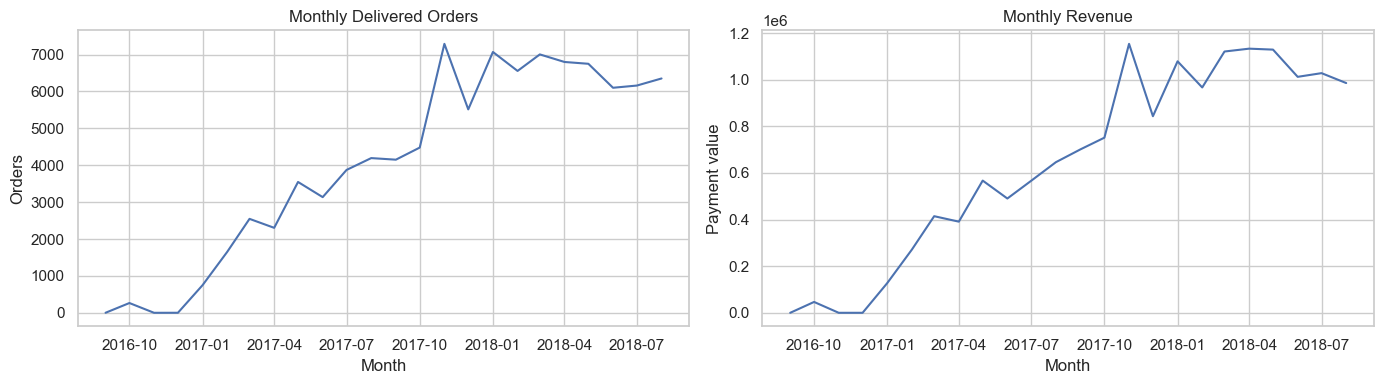

,order_purchase_timestamp,orders,revenue
14,2017-11-01,7289,1153528.05
15,2017-12-01,5513,843199.17
16,2018-01-01,7069,1078606.86
17,2018-02-01,6555,966510.88
18,2018-03-01,7003,1120678.00
19,2018-04-01,6798,1132933.95
20,2018-05-01,6749,1128836.69
21,2018-06-01,6099,1012090.68
22,2018-07-01,6159,1027903.86
23,2018-08-01,6351,985414.28


In [4]:
print("Summary of order payment value:")
display(order_data["order_payment_value"].describe().to_frame().round(2))
monthly_orders = (
    order_data.set_index("order_purchase_timestamp")
    .resample("MS")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("order_payment_value", "sum")
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(
    data=monthly_orders, x="order_purchase_timestamp",
    y="orders", ax=axes[0]
)
axes[0].set_title("Monthly Delivered Orders")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Orders")

sns.lineplot(
    data=monthly_orders, x="order_purchase_timestamp",
    y="revenue", ax=axes[1]
)
axes[1].set_title("Monthly Revenue")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Payment value")

plt.tight_layout()
plt.show()
display(monthly_orders.tail(10))

## Customer-Level Metrics: RFM and CLV Proxy

In [5]:
reference_date = (
    order_data["order_purchase_timestamp"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = order_data.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    first_purchase=("order_purchase_timestamp", "min"),
    frequency=("order_id", "nunique"),
    monetary=("order_payment_value", "sum")
).reset_index()

rfm["recency"] = (
    reference_date - rfm["last_purchase"].dt.normalize()
).dt.days
rfm["average_order_value"] = (
    rfm["monetary"] / rfm["frequency"].clip(lower=1)
)

# Simple historical CLV proxy: total observed customer payment value.
rfm["clv_proxy"] = rfm["monetary"]
print("RFM reference date:", reference_date.date())
print("Customer-level rows:", len(rfm))
display(rfm.head())
display(rfm[[
    "recency", "frequency", "monetary",
    "average_order_value", "clv_proxy"
]].describe().round(2))

RFM reference date: 2018-08-30
Customer-level rows: 93358


,customer_unique_id,last_purchase,first_purchase,frequency,monetary,recency,average_order_value,clv_proxy
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,2018-05-10 10:56:27,1,141.90,112,141.90,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,2018-05-07 11:11:27,1,27.19,115,27.19,27.19
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,2017-03-10 21:05:03,1,86.22,538,86.22,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,2017-10-12 20:29:41,1,43.62,322,43.62,43.62
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,2017-11-14 19:45:42,1,196.89,289,196.89,196.89


,recency,frequency,monetary,average_order_value,clv_proxy
count,93358.00,93358.00,93358.00,93358.00,93358.00
mean,238.48,1.03,165.20,160.31,165.20
std,152.60,0.21,226.31,219.57,226.31
min,1.00,1.00,0.00,0.00,0.00
25%,115.00,1.00,63.05,62.37,63.05
50%,219.00,1.00,107.78,105.63,107.78
75%,347.00,1.00,182.56,176.65,182.56
max,714.00,15.00,13664.08,13664.08,13664.08


## RFM Score Calculation

In [6]:
def quantile_score(series, bins=4, higher_is_better=True):
    ranked = series.rank(method="first", ascending=True)
    labels = list(range(1, bins + 1))
    if not higher_is_better:
        labels = labels[::-1]
    return pd.qcut(ranked, q=bins, labels=labels).astype(int)

rfm["R_score"] = quantile_score(
    rfm["recency"], higher_is_better=False
)
rfm["F_score"] = quantile_score(
    rfm["frequency"], higher_is_better=True
)
rfm["M_score"] = quantile_score(
    rfm["monetary"], higher_is_better=True
)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

display(rfm[[
    "customer_unique_id", "recency", "frequency", "monetary",
    "R_score", "F_score", "M_score", "RFM_score"
]].head())

,customer_unique_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,3,413
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,4,1,1,411
2,0000f46a3911fa3c0805444483337064,538,1,86.22,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,322,1,43.62,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,289,1,196.89,2,1,4,214


## Customer Segmentation Using K-Means

In [7]:
# Log-transform skewed metrics before scaling.
rfm_features = rfm[["recency", "frequency", "monetary"]].copy()
rfm_features["frequency"] = np.log1p(rfm_features["frequency"])
rfm_features["monetary"] = np.log1p(
    rfm_features["monetary"].clip(lower=0)
)

rfm_scaler = StandardScaler()
rfm_scaled = rfm_scaler.fit_transform(rfm_features)

kmeans = KMeans(
    n_clusters=4, random_state=RANDOM_STATE, n_init=10
)
rfm["cluster"] = kmeans.fit_predict(rfm_scaled)

cluster_profile = rfm.groupby("cluster").agg(
    customers=("customer_unique_id", "nunique"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean"),
    total_revenue=("monetary", "sum")
).sort_values("avg_monetary", ascending=False)

# Give each cluster a readable label based on its observed profile.
ordered_clusters = cluster_profile.sort_values(
    ["avg_monetary", "avg_recency"],
    ascending=[False, True]
).index.tolist()

segment_labels = [
    "High Value", "Potential Value",
    "Low Value", "Low Spend / Review"
]
segment_map = {
    cluster_id: segment_labels[i]
    for i, cluster_id in enumerate(ordered_clusters)
}
rfm["segment"] = rfm["cluster"].map(segment_map)

display(cluster_profile.round(2))
display(rfm[[
    "customer_unique_id", "cluster", "segment",
    "recency", "frequency", "monetary"
]].head())

,customers,avg_recency,avg_frequency,avg_monetary,total_revenue
cluster,,,,,
0,27665,174.27,1.00,319.62,8842410.38
2,2801,220.81,2.11,308.59,864357.21
3,27114,425.38,1.00,119.33,3235636.86
1,35778,147.87,1.00,69.32,2480057.32


,customer_unique_id,cluster,segment,recency,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,0,High Value,112,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,Low Spend / Review,115,1,27.19
2,0000f46a3911fa3c0805444483337064,3,Low Value,538,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,3,Low Value,322,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,0,High Value,289,1,196.89


## RFM Visualizations and Customer Segment Profiling

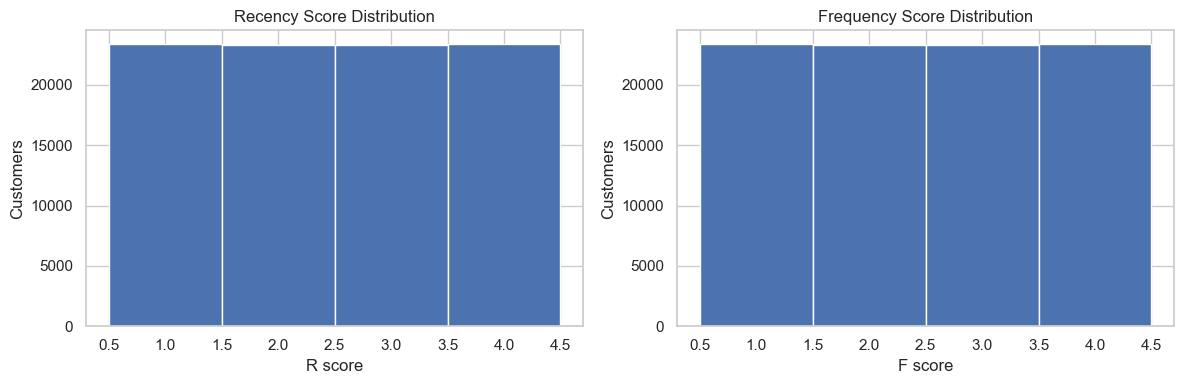

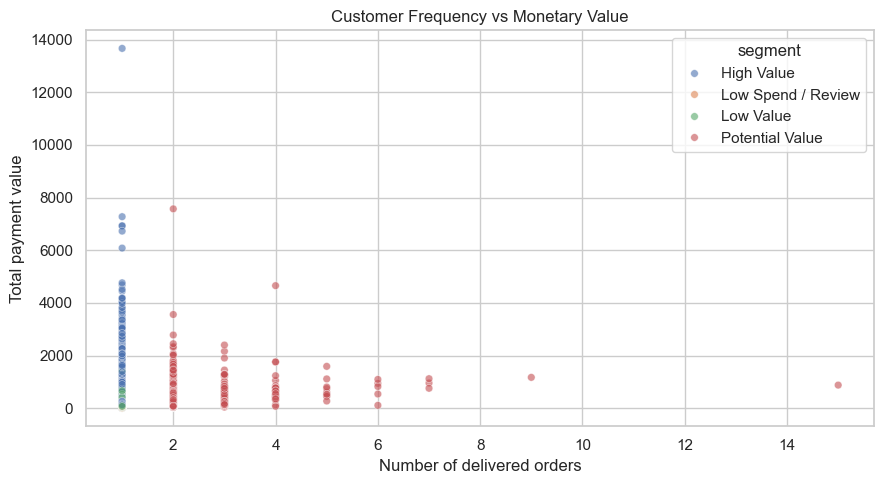

,segment,customers,total_revenue,avg_order_value,avg_recency,avg_frequency,avg_clv_proxy
0,High Value,27665,8842410.38,319.62,174.27,1.00,319.62
1,Low Spend / Review,35778,2480057.32,69.32,147.87,1.00,69.32
2,Low Value,27114,3235636.86,119.33,425.38,1.00,119.33
3,Potential Value,2801,864357.21,145.87,220.81,2.11,308.59


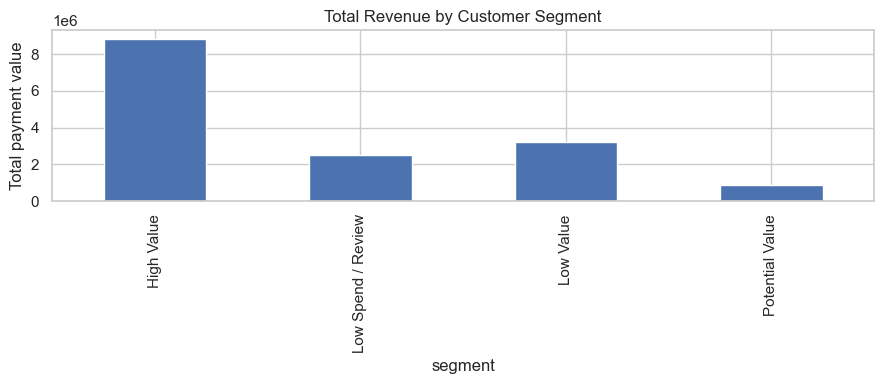

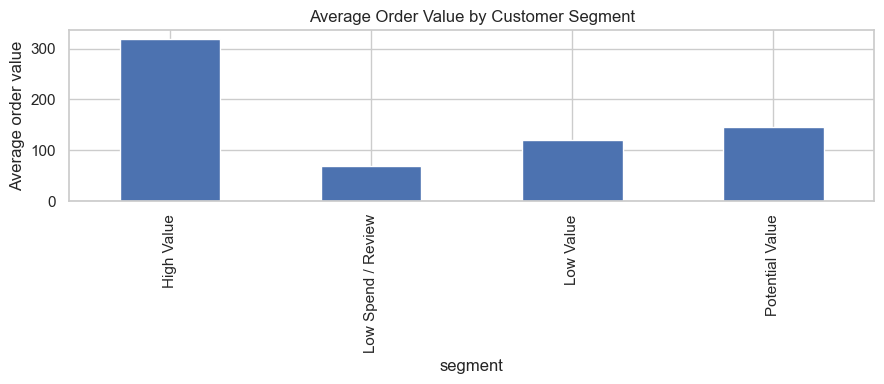

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rfm["R_score"].hist(
    bins=np.arange(0.5, 5.5, 1), ax=axes[0]
)
axes[0].set_title("Recency Score Distribution")
axes[0].set_xlabel("R score")
axes[0].set_ylabel("Customers")

rfm["F_score"].hist(
    bins=np.arange(0.5, 5.5, 1), ax=axes[1]
)
axes[1].set_title("Frequency Score Distribution")
axes[1].set_xlabel("F score")
axes[1].set_ylabel("Customers")

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=rfm, x="frequency", y="monetary",
    hue="segment", alpha=0.6, s=30
)
plt.title("Customer Frequency vs Monetary Value")
plt.xlabel("Number of delivered orders")
plt.ylabel("Total payment value")
plt.tight_layout()
plt.show()

segment_summary = rfm.groupby("segment").agg(
    customers=("customer_unique_id", "nunique"),
    total_revenue=("monetary", "sum"),
    avg_order_value=("average_order_value", "mean"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_clv_proxy=("clv_proxy", "mean")
).reset_index()

display(segment_summary.round(2))

segment_summary.plot(
    x="segment", y="total_revenue", kind="bar",
    figsize=(9, 4), legend=False,
    title="Total Revenue by Customer Segment"
)
plt.ylabel("Total payment value")
plt.tight_layout()
plt.show()

segment_summary.plot(
    x="segment", y="avg_order_value", kind="bar",
    figsize=(9, 4), legend=False,
    title="Average Order Value by Customer Segment"
)
plt.ylabel("Average order value")
plt.tight_layout()
plt.show()

## Cohort Analysis and Customer Retention

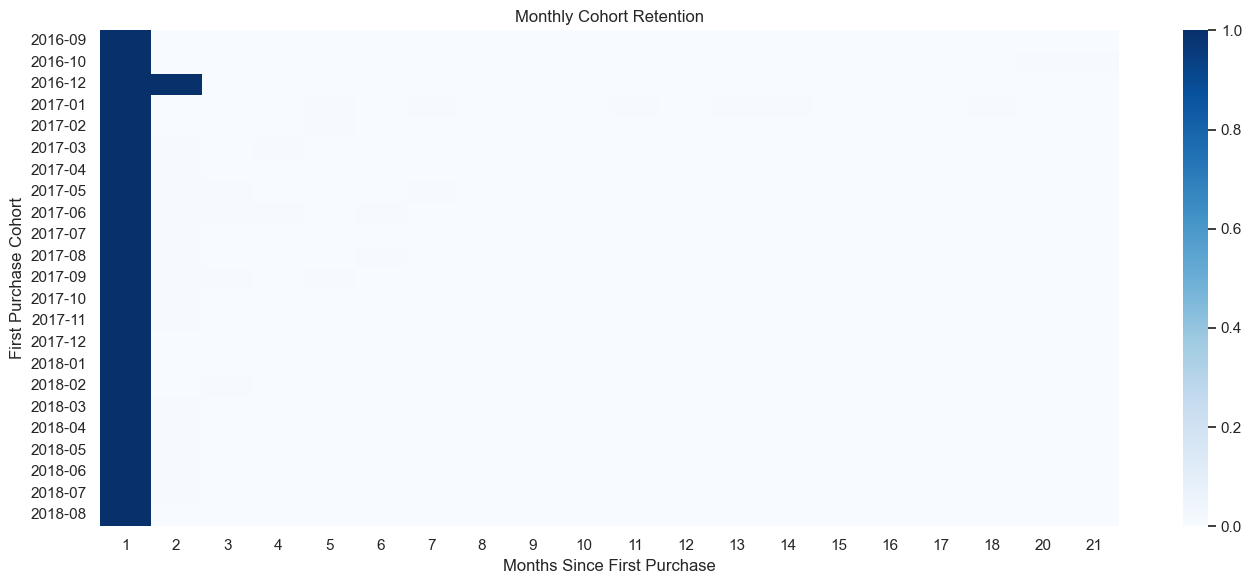

In [9]:
cohort_data = order_data[[
    "customer_unique_id", "order_purchase_timestamp"
]].copy()

cohort_data["order_month"] = (
    cohort_data["order_purchase_timestamp"].dt.to_period("M")
)
cohort_data["cohort_month"] = (
    cohort_data.groupby("customer_unique_id")["order_month"]
    .transform("min")
)
cohort_data["cohort_index"] = (
    (cohort_data["order_month"].dt.year - cohort_data["cohort_month"].dt.year) * 12
    + cohort_data["order_month"].dt.month
    - cohort_data["cohort_month"].dt.month
    + 1
)

cohort_counts = cohort_data.groupby(
    ["cohort_month", "cohort_index"]
)["customer_unique_id"].nunique().unstack(fill_value=0)

retention = cohort_counts.div(cohort_counts.iloc[:, 0], axis=0)

plt.figure(figsize=(14, 6))
sns.heatmap(retention, cmap="Blues", vmin=0, vmax=1)
plt.title("Monthly Cohort Retention")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Cohort")
plt.tight_layout()
plt.show()

## Churn Definition and Target Construction


In [10]:
latest_timestamp = order_data["order_purchase_timestamp"].max()
latest_date = latest_timestamp.normalize()

# Snapshot is 90 days before the final date in the dataset.
snapshot_date = latest_date - pd.Timedelta(days=90)
label_end_exclusive = snapshot_date + pd.Timedelta(days=91)

history = order_data.loc[
    order_data["order_purchase_timestamp"] < snapshot_date
].copy()

future_orders = order_data.loc[
    (order_data["order_purchase_timestamp"] >= snapshot_date)
    & (order_data["order_purchase_timestamp"] < label_end_exclusive),
    ["customer_unique_id", "order_id"]
].drop_duplicates()

model_data = history.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    first_purchase=("order_purchase_timestamp", "min"),
    frequency=("order_id", "nunique"),
    monetary=("order_payment_value", "sum"),
    city=("customer_city", "first"),
    state=("customer_state", "first")
).reset_index()

model_data["recency"] = (
    snapshot_date - model_data["last_purchase"].dt.normalize()
).dt.days
model_data["customer_age_days"] = (
    snapshot_date - model_data["first_purchase"].dt.normalize()
).dt.days
model_data["average_order_value"] = (
    model_data["monetary"] / model_data["frequency"].clip(lower=1)
)
model_data["clv_proxy"] = model_data["monetary"]

future_customer_ids = set(future_orders["customer_unique_id"].unique())

# Consistent target: 1 = Churn, 0 = Retained.
model_data["churn"] = (
    ~model_data["customer_unique_id"].isin(future_customer_ids)
).astype(int)

print("Snapshot date:", snapshot_date.date())
print("Label window ends before:", label_end_exclusive.date())
print("Customers available for modelling:", len(model_data))

target_summary = model_data["churn"].map({
    1: "Churn", 0: "Retained"
}).value_counts().to_frame("customers")
target_summary["percentage"] = (
    target_summary["customers"] / target_summary["customers"].sum() * 100
)
display(target_summary.round(2))

Snapshot date: 2018-05-31
Label window ends before: 2018-08-30
Customers available for modelling: 75260


,customers,percentage
churn,,
Churn,74838,99.44
Retained,422,0.56


## Feature Engineering and Train-Test Split

In [11]:
feature_cols = [
    "recency", "frequency", "monetary",
    "customer_age_days", "average_order_value"
]

X = model_data[feature_cols].replace([np.inf, -np.inf], np.nan)
y = model_data["churn"]  # 1 = Churn, 0 = Retained

class_counts = y.value_counts()
if y.nunique() != 2 or class_counts.min() < 2:
    raise ValueError(
        "Both classes need at least two rows. Review the snapshot and label period."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training distribution:")
display(y_train.map({1: "Churn", 0: "Retained"}).value_counts().to_frame("customers"))
print("Test distribution:")
display(y_test.map({1: "Churn", 0: "Retained"}).value_counts().to_frame("customers"))

Training rows: 56445
Test rows: 18815
Training distribution:


,customers
churn,
Churn,56129
Retained,316


Test distribution:


,customers
churn,
Churn,18709
Retained,106


## Churn Classification Model Training

The three required models are Logistic Regression, Random Forest and Gradient Boosting.

In [12]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000, class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=250, min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(
            random_state=RANDOM_STATE
        ))
    ])
}

fitted_models = {}
model_rows = []

for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    fitted_models[name] = estimator

    predictions = estimator.predict(X_test)
    probabilities = estimator.predict_proba(X_test)[:, 1]

    model_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Churn Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Churn Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Churn F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(y_test, probabilities)
            if y_test.nunique() == 2 else np.nan
        )
    })

model_results = pd.DataFrame(model_rows).sort_values(
    ["Churn Recall", "ROC-AUC", "Churn F1 Score"],
    ascending=False
).reset_index(drop=True)

display(model_results.round(3))

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1 Score,ROC-AUC
0,Random Forest,0.993,0.994,0.999,0.997,0.557
1,Gradient Boosting,0.993,0.994,0.999,0.997,0.581
2,Logistic Regression,0.584,0.996,0.584,0.736,0.625


## Model Evaluation and Confusion Matrix Analysis


Model: Logistic Regression
---------------------------------------------
Confusion matrix (rows=true, columns=predicted; 1=Churn):
[[   61    45]
 [ 7789 10920]]
              precision    recall  f1-score   support

    Retained       0.01      0.58      0.02       106
       Churn       1.00      0.58      0.74     18709

    accuracy                           0.58     18815
   macro avg       0.50      0.58      0.38     18815
weighted avg       0.99      0.58      0.73     18815


Model: Random Forest
---------------------------------------------
Confusion matrix (rows=true, columns=predicted; 1=Churn):
[[    0   106]
 [   19 18690]]
              precision    recall  f1-score   support

    Retained       0.00      0.00      0.00       106
       Churn       0.99      1.00      1.00     18709

    accuracy                           0.99     18815
   macro avg       0.50      0.50      0.50     18815
weighted avg       0.99      0.99      0.99     18815


Model: Gradient Boosting


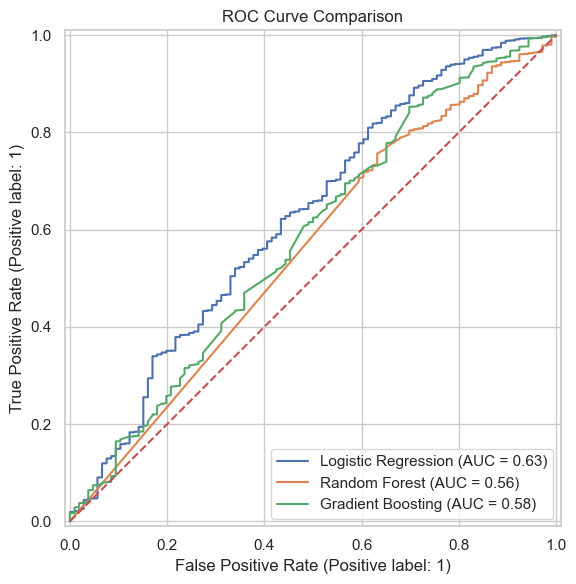

In [13]:
for name, estimator in fitted_models.items():
    predictions = estimator.predict(X_test)

    print("\nModel:", name)
    print("-" * 45)
    print("Confusion matrix (rows=true, columns=predicted; 1=Churn):")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))

    print(classification_report(
        y_test, predictions,
        labels=[0, 1],
        target_names=["Retained", "Churn"],
        zero_division=0
    ))

fig, ax = plt.subplots(figsize=(8, 6))
for name, estimator in fitted_models.items():
    RocCurveDisplay.from_predictions(
        y_test,
        estimator.predict_proba(X_test)[:, 1],
        name=name,
        ax=ax
    )
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

## Churn Probability Threshold Analysis

In [14]:
threshold_rows = []

for name, estimator in fitted_models.items():
    churn_probability = estimator.predict_proba(X_test)[:, 1]

    for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
        predictions = (churn_probability >= threshold).astype(int)

        threshold_rows.append({
            "Model": name,
            "Threshold": threshold,
            "Churn Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Churn Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "Churn F1 Score": f1_score(
                y_test, predictions, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(3))

,Model,Threshold,Churn Precision,Churn Recall,Churn F1 Score
0,Logistic Regression,0.1,0.994,0.998,0.996
1,Logistic Regression,0.2,0.995,0.994,0.994
2,Logistic Regression,0.3,0.995,0.988,0.991
3,Logistic Regression,0.4,0.995,0.978,0.986
4,Logistic Regression,0.5,0.996,0.584,0.736
5,Logistic Regression,0.6,0.997,0.125,0.223
6,Logistic Regression,0.7,1.000,0.009,0.017
7,Random Forest,0.1,0.994,1.000,0.997
8,Random Forest,0.2,0.994,1.000,0.997
9,Random Forest,0.3,0.994,1.000,0.997


## Model Comparison and Customer Risk Scoring

In [15]:
# Select the model with the strongest churn recall; use ROC-AUC and F1 as tie-breakers.
best_model_name = model_results.sort_values(
    ["Churn Recall", "ROC-AUC", "Churn F1 Score"],
    ascending=False
).iloc[0]["Model"]

best_model = fitted_models[best_model_name]
print("Selected model:", best_model_name)
print("Selection basis: churn recall, then ROC-AUC and churn F1.")
print("Check precision as well; high recall can come with many false positives.")

model_data["predicted_churn_probability"] = best_model.predict_proba(
    X
)[:, 1]

# 0.50 is a transparent starting threshold, not a universally optimal value.
risk_threshold = 0.50
model_data["predicted_churn"] = (
    model_data["predicted_churn_probability"] >= risk_threshold
).astype(int)

display(
    model_data.sort_values(
        "predicted_churn_probability", ascending=False
    )[[
        "customer_unique_id", "recency", "frequency",
        "monetary", "predicted_churn_probability", "predicted_churn"
    ]].head(10)
)

Selected model: Random Forest
Selection basis: churn recall, then ROC-AUC and churn F1.
Check precision as well; high recall can come with many false positives.


,customer_unique_id,recency,frequency,monetary,predicted_churn_probability,predicted_churn
75259,ffffd2657e2aad2907e67c3e9daecbeb,394,1,71.56,1.0,1
61783,d1d123410c240b9ab053ce79b566b6c8,79,1,29.38,1.0,1
61782,d1d072b394ad1c5ad7a9161d72112606,111,1,50.01,1.0,1
61781,d1cef5e76eb0afdb1bf1868fa9bf227f,332,1,96.94,1.0,1
36413,7ba5ab975c54be79464d74a8c03b5723,469,1,73.46,1.0,1
36414,7ba5f632184aa9987fe77099c9e88c06,24,1,99.90,1.0,1
36415,7ba686b47812b130642ab6e74edf9b4d,157,1,53.79,1.0,1
61780,d1ce28c9423d75b153a228199ac3e8f4,126,1,211.74,1.0,1
36417,7ba78279a5adfe45def44f1d59fdae72,25,1,273.83,1.0,1
61777,d1ccd6d8797a035e6a89fb3efab3cad8,398,1,150.04,1.0,1


## High-Risk Customer Identification and Action List

In [16]:
# Merge segment labels from the full-period RFM table for dashboard context.
scored_customers = model_data.merge(
    rfm[["customer_unique_id", "segment", "RFM_score", "clv_proxy"]],
    on="customer_unique_id",
    how="left",
    suffixes=("", "_full_period")
)

risk_threshold = 0.70
high_risk_customers = scored_customers.loc[
    scored_customers["predicted_churn_probability"] >= risk_threshold
].copy()

# A marketing action list prioritising high-value customers with high model risk.
high_value_cutoff = scored_customers["clv_proxy"].quantile(0.75)
action_list = high_risk_customers.loc[
    high_risk_customers["clv_proxy"] >= high_value_cutoff
].sort_values(
    "predicted_churn_probability", ascending=False
)

print("Customers above risk threshold:", len(high_risk_customers))
print("High-value, high-risk customers:", len(action_list))
display(action_list[[
    "customer_unique_id", "segment", "clv_proxy",
    "predicted_churn_probability", "predicted_churn"
]].head(20))

Customers above risk threshold: 74711
High-value, high-risk customers: 18682


,customer_unique_id,segment,clv_proxy,predicted_churn_probability,predicted_churn
4,0004aac84e0df4da2b147fca70cf8255,High Value,196.89,1.0,1
45532,9aadd067754a7ee9a33384472d879231,High Value,229.34,1.0,1
45434,9a5c4df1326945af470ac50fa853441b,High Value,335.10,1.0,1
45436,9a60784678a900f0bf537e3b9bd9f736,Low Value,214.36,1.0,1
45443,9a64d52406f314dcbd5029f513f5ff12,High Value,396.32,1.0,1
45453,9a6e43453bf93c75cd740563c2872697,High Value,198.13,1.0,1
45454,9a6ebfbeb5d9f2d280e3c872b750fc39,Low Value,296.61,1.0,1
45459,9a736b248f67d166d2fbb006bcb877c3,Potential Value,233.49,1.0,1
45466,9a7b38b233981ed1c50933addaa34a08,High Value,415.02,1.0,1
45473,9a81c7dc0ab471b009bc6c0b3fd8ec1d,High Value,1017.52,1.0,1


## SQL-Based Customer Aggregation Using SQLite

In [17]:
sql_source = order_data[[
    "order_id", "customer_unique_id",
    "order_purchase_timestamp", "order_payment_value"
]].copy()

with sqlite3.connect(":memory:") as connection:
    sql_source.to_sql("orders", connection, index=False, if_exists="replace")

    sql_customer_summary = pd.read_sql_query(
        '''
        SELECT
            customer_unique_id,
            COUNT(DISTINCT order_id) AS frequency,
            SUM(order_payment_value) AS monetary,
            MAX(order_purchase_timestamp) AS last_purchase
        FROM orders
        GROUP BY customer_unique_id
        ORDER BY monetary DESC
        LIMIT 10
        ''',
        connection
    )

display(sql_customer_summary)

,customer_unique_id,frequency,monetary,last_purchase
0,0a0a92112bd4c708ca5fde585afaa872,1,13664.08,2017-09-29 15:24:52
1,da122df9eeddfedc1dc1f5349a1a690c,2,7571.63,2017-04-01 15:58:41
2,763c8b1c9c68a0229c42c9fc6f662b93,1,7274.88,2018-07-15 14:49:44
3,dc4802a71eae9be1dd28f5d788ceb526,1,6929.31,2017-02-12 20:37:36
4,459bef486812aa25204be022145caa62,1,6922.21,2018-07-25 18:10:17
5,ff4159b92c40ebe40454e3e6a7c35ed6,1,6726.66,2017-05-24 18:14:34
6,4007669dec559734d6f53e029e360987,1,6081.54,2017-11-24 11:03:35
7,eebb5dda148d3893cdaf5b5ca3040ccb,1,4764.34,2017-04-18 18:50:13
8,48e1ac109decbb87765a3eade6854098,1,4681.78,2018-06-22 12:23:19
9,c8460e4251689ba205045f3ea17884a1,4,4655.91,2018-08-08 14:27:15


## Retention KPIs and Business Insights

In [18]:
total_customers = int(rfm["customer_unique_id"].nunique())
total_revenue = float(rfm["monetary"].sum())
overall_average_order_value = float(
    order_data["order_payment_value"].sum()
    / max(order_data["order_id"].nunique(), 1)
)
historical_churn_rate = float(model_data["churn"].mean())
retention_rate = 1 - historical_churn_rate
one_order_customers = int((rfm["frequency"] == 1).sum())
one_order_share = one_order_customers / max(total_customers, 1)
top_segment = segment_summary.sort_values(
    "total_revenue", ascending=False
).iloc[0]
top_segment_revenue_share = top_segment["total_revenue"] / max(total_revenue, 1)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total customers in full-period RFM",
        "Total delivered-order payment value",
        "Average order value",
        "Historical 90-day churn rate in modelling snapshot",
        "Historical 90-day retention rate in modelling snapshot",
        "Customers with one delivered order",
        "Share of customers with one delivered order",
        "Highest-revenue segment",
        "Revenue share of highest-revenue segment"
    ],
    "Value": [
        total_customers,
        round(total_revenue, 2),
        round(overall_average_order_value, 2),
        f"{historical_churn_rate:.2%}",
        f"{retention_rate:.2%}",
        one_order_customers,
        f"{one_order_share:.2%}",
        top_segment["segment"],
        f"{top_segment_revenue_share:.2%}"
    ]
})
display(kpi_summary)

print("DATA-BASED BUSINESS INSIGHTS")
print(f"1. The dataset contains {total_customers:,} unique customers in the RFM analysis.")
print(f"2. Total delivered-order payment value is {total_revenue:,.2f}.")
print(f"3. Average order value is {overall_average_order_value:,.2f}.")
print(f"4. {one_order_share:.1%} of customers placed only one delivered order.")
print(f"5. The highest-revenue segment is '{top_segment['segment']}', contributing {top_segment_revenue_share:.1%} of observed revenue.")
print(f"6. The historical 90-day churn label rate in the modelling snapshot is {historical_churn_rate:.1%}.")
print(f"7. The model selected for further review is {best_model_name}; its churn recall is "
      f"{model_results.loc[model_results['Model'] == best_model_name, 'Churn Recall'].iloc[0]:.3f}.")
print(f"8. {len(action_list):,} customers are both above the example risk threshold and in the top quartile of historical monetary value.")
print("\nInterpret these findings in context; churn labels and model scores are not guarantees.")

,KPI,Value
0,Total customers in full-period RFM,93358
1,Total delivered-order payment value,15422461.77
2,Average order value,159.85
3,Historical 90-day churn rate in modelling snap...,99.44%
4,Historical 90-day retention rate in modelling ...,0.56%
5,Customers with one delivered order,90557
6,Share of customers with one delivered order,97.00%
7,Highest-revenue segment,High Value
8,Revenue share of highest-revenue segment,57.33%


DATA-BASED BUSINESS INSIGHTS
1. The dataset contains 93,358 unique customers in the RFM analysis.
2. Total delivered-order payment value is 15,422,461.77.
3. Average order value is 159.85.
4. 97.0% of customers placed only one delivered order.
5. The highest-revenue segment is 'High Value', contributing 57.3% of observed revenue.
6. The historical 90-day churn label rate in the modelling snapshot is 99.4%.
7. The model selected for further review is Random Forest; its churn recall is 0.999.
8. 18,682 customers are both above the example risk threshold and in the top quartile of historical monetary value.

Interpret these findings in context; churn labels and model scores are not guarantees.


## Exporting Datasets for Power BI and Submission

In [19]:
rfm.to_csv("customer_rfm_segments.csv", index=False)
segment_summary.to_csv("segment_summary.csv", index=False)
monthly_orders.to_csv("monthly_order_revenue.csv", index=False)
retention.to_csv("cohort_retention.csv")
model_data.to_csv("customer_churn_scored.csv", index=False)
high_risk_customers.to_csv("high_risk_customer_list.csv", index=False)
action_list.to_csv("high_value_high_risk_action_list.csv", index=False)
model_results.to_csv("model_comparison.csv", index=False)
threshold_df.to_csv("churn_threshold_comparison.csv", index=False)
kpi_summary.to_csv("project_kpi_summary.csv", index=False)

exported_files = [
    "customer_rfm_segments.csv",
    "segment_summary.csv",
    "monthly_order_revenue.csv",
    "cohort_retention.csv",
    "customer_churn_scored.csv",
    "high_risk_customer_list.csv",
    "high_value_high_risk_action_list.csv",
    "model_comparison.csv",
    "churn_threshold_comparison.csv",
    "project_kpi_summary.csv"
]

print("Export completed:")
for filename in exported_files:
    print("-", filename)

Export completed:
- customer_rfm_segments.csv
- segment_summary.csv
- monthly_order_revenue.csv
- cohort_retention.csv
- customer_churn_scored.csv
- high_risk_customer_list.csv
- high_value_high_risk_action_list.csv
- model_comparison.csv
- churn_threshold_comparison.csv
- project_kpi_summary.csv
